# 2.5.2 Tương phản tổn thương–da thấp

Notebook đi theo thứ tự: mô tả vấn đề, chứng minh vấn đề, nhóm ảnh gặp phải, tỉ lệ ảnh gặp vấn đề, phương pháp đề xuất, chạy thực nghiệm, so sánh dự đoán trên mẫu 100 ảnh.

**Kiểm soát biến:** chỉ thay đổi phép tiền xử lý; giữ nguyên split theo `lesion_id`, seed 42–44 và cấu hình đóng băng ở `src/training.py` (ResNet-18, 224×224, AdamW lr 1e-4, batch 32, 20 epoch, WRS, flip).

**GPU RTX 3050 4 GB:** giữ AMP, `cudnn.benchmark`, ảnh cache trong RAM và flip + normalize trên GPU. Batch 32 không đổi vì sẽ phá tính so sánh.

Test không dùng để chọn phương pháp. Mọi số đọc từ `outputs/`, đầu ra lượt này ở `outputs/rerun_2.5/` và `outputs/figures/rerun_2.5/`.

In [1]:
# Chạy từ gốc repo. Mọi tính toán nằm ở src/preprocess/problem_report.py để hai notebook dùng đúng một quy trình.
import pandas as pd
from IPython.display import display
from src.preprocess import problem_report as R

pd.set_option("display.width", 200, "display.max_columns", 40, "display.max_colwidth", 80)
KEY = "contrast"
D = R.load_table()
print(R.PROBLEMS[KEY]["name"], "| số ảnh:", len(D))

Tương phản tổn thương–da thấp | số ảnh: 10015


## 1. Mô tả vấn đề

**Tương phản tổn thương–da thấp** là khi tổn thương có độ sáng gần giống da xung quanh, ranh giới khó thấy. Nguyên nhân có thể là tổn thương ít sắc tố, phẳng, hoặc ánh sáng khuếch tán khi chụp.

**Vì sao có thể hại CNN:** ranh giới và hình dạng tổn thương là đặc trưng quan trọng; khi chênh lệch sáng nhỏ, tín hiệu đó yếu.

**Vì sao có thể không hại:** tương phản thấp có thể là đặc điểm của chính lớp bệnh, và CNN có thể dựa vào màu hoặc kết cấu thay vì độ sáng.

**Cách đo (bộ đo EDA):** `contrast` = mức xám trung bình của da − mức xám trung bình của tổn thương, tổn thương lấy bằng **mask Otsu thô**. **Cờ `F_low_contrast`:** contrast < 20 mức xám (khoảng 8% dải 0–255). Mask sai thì chỉ số sai, nên phần dưới kiểm tra mask bằng ảnh.

## 2. Chứng minh vấn đề

Phần này kiểm tra nhóm tương phản thấp nằm ở đâu trong phân phối chung, và lược đồ xám của ảnh điển hình trông khác ảnh thường ra sao.

,contrast
n ảnh có đo,10014.000
trung vị,60.369
Q1,40.762
Q3,80.556
min,-2.149
max,181.356
ngưỡng cờ,20.000
trung vị nhóm cờ,16.486
trung vị còn lại,62.103


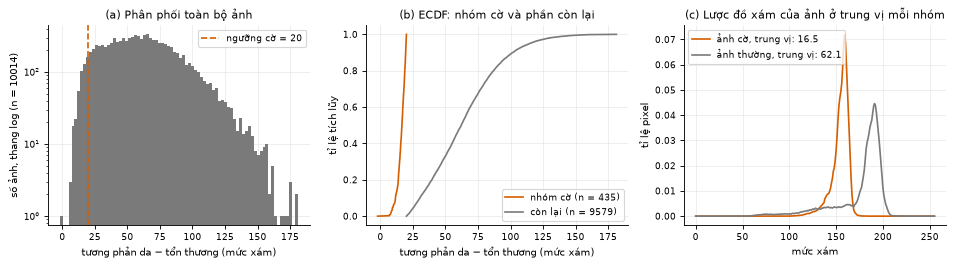

In [2]:
display(R.evidence_table(D, KEY).round(3))
R.fig_evidence(D, KEY);

**Bằng chứng độc lập với cờ.** So nhóm cờ và phần còn lại trên đúng chỉ số dùng để gắn cờ thì khác biệt là hiển nhiên, nên bảng dưới dùng chỉ số khác, một ảnh mỗi lesion. Cliff's δ: dưới 0,147 không đáng kể, dưới 0,33 nhỏ, dưới 0,474 vừa, từ đó trở lên lớn.

In [3]:
display(R.independent_evidence(D, KEY).round(3))

,chỉ số,nguồn,n cờ,n còn lại,trung vị cờ,trung vị còn lại,Cliff δ
0,độ lệch chuẩn mức xám,toàn bộ dữ liệu,280,7190,12.242,25.963,-0.902
1,khoảng phân vị 5–95,toàn bộ dữ liệu,280,7190,38.000,83.000,-0.889
2,entropy,toàn bộ dữ liệu,280,7190,5.543,6.153,-0.652


**Ảnh minh họa, chọn có hệ thống:** 6 ảnh bị cờ và 6 ảnh thường, cách đều theo thứ tự chỉ số. Dưới mỗi ảnh là đường bao mask Otsu thô, để thấy khi nào chỉ số đáng tin. Một số ảnh bị cờ có thể do mask sai, nên tỉ lệ ở mục 4 là ước lượng.

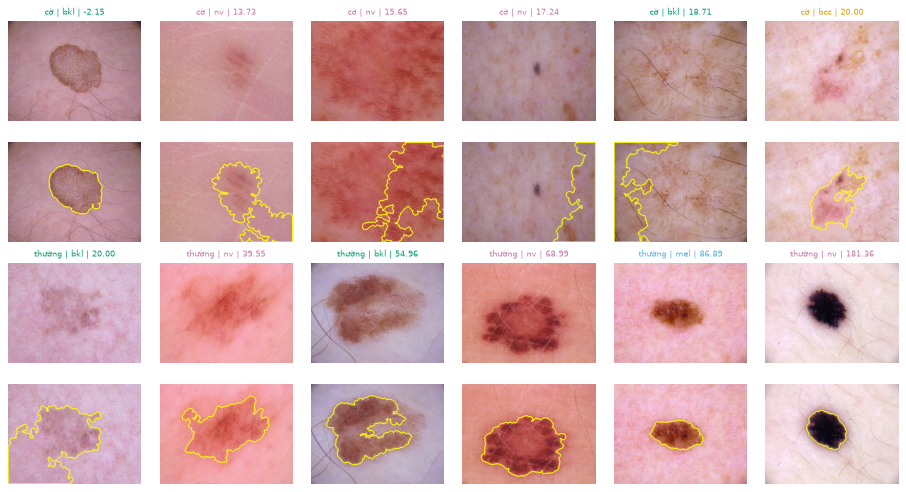

In [4]:
R.fig_examples(D, KEY);

**Độ tin cậy của mask.** Bảng dưới là kết quả soát mask Otsu trên một mẫu ảnh tương phản thấp (`outputs/preprocess/lowcontrast_mask_audit.csv`). Việc soát do AI đánh giá bằng mắt và **cần người trong nhóm xác nhận**. Ảnh có mask sai không thật sự chứng minh tương phản thấp, nên nhóm cờ này lẫn cả ảnh do bộ đo sai.

In [5]:
display(R.mask_audit())

,đánh giá mask,số ảnh,tỉ lệ %
0,sai,11,45.8
1,đúng,8,33.3
2,một phần,5,20.8


## 3. Các nhóm ảnh gặp phải

Tỉ lệ ảnh bị cờ theo lớp bệnh, vùng cơ thể, cách gán nhãn, tuổi, giới, kèm CI95 Wilson. Kiểm định chi-square và Cramér's V tính trên một ảnh mỗi lesion, hiệu chỉnh Holm. n lớn nên p gần như luôn nhỏ, cần đọc Cramér's V. Đây là liên quan, chưa phải nguyên nhân: cờ có thể phản ánh nguồn chụp khác nhau.

,yếu tố,n lesion,chi2,p,Cramér V,p Holm
0,Lớp bệnh,7470,242.5478,0.0000,0.1802,0.0000
1,Vùng cơ thể,7264,156.0355,0.0000,0.1466,0.0000
2,Cách gán nhãn,7470,88.8641,0.0000,0.1091,0.0000
3,Nhóm tuổi,7418,29.6621,0.0000,0.0632,0.0000
4,Giới,7420,3.1201,0.0773,0.0205,0.0773


,yếu tố,nhóm,n ảnh,n cờ,tỉ lệ %,CI thấp %,CI cao %
0,Lớp bệnh,akiec,327,42,12.84,9.64,16.91
1,Lớp bệnh,bcc,514,79,15.37,12.51,18.74
2,Lớp bệnh,bkl,1099,114,10.37,8.71,12.32
3,Lớp bệnh,df,115,11,9.57,5.43,16.32
4,Lớp bệnh,mel,1113,15,1.35,0.82,2.21
5,Lớp bệnh,nv,6705,168,2.51,2.16,2.91
6,Lớp bệnh,vasc,142,6,4.23,1.95,8.91
7,Vùng cơ thể,abdomen,1022,21,2.05,1.35,3.12
8,Vùng cơ thể,back,2192,87,3.97,3.23,4.87
9,Vùng cơ thể,chest,407,26,6.39,4.40,9.20


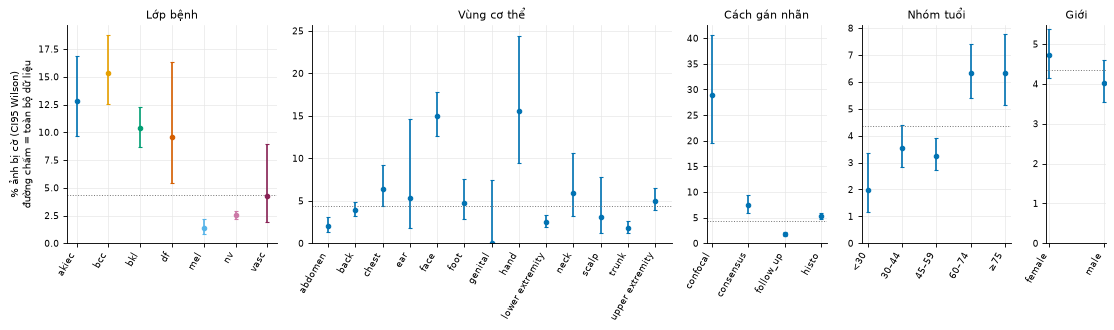

In [6]:
R.fig_groups(D, KEY);
display(R.group_tests(D, KEY).round(4))
display(R.group_rates(D, KEY).drop(columns='cột').round(2))

## 4. Tỉ lệ ảnh gặp vấn đề

Số ảnh bị cờ trên toàn bộ và từng tập, và độ nhạy theo ngưỡng để kết luận không phụ thuộc một ngưỡng duy nhất.

In [7]:
display(R.prevalence(D, KEY).round(2))
display(R.threshold_sensitivity(D, KEY).round(3))

,tập,n ảnh,n cờ,tỉ lệ %,n lesion cờ
0,toàn bộ,10015,435,4.34,381
1,train,6408,275,4.29,241
2,val,1603,71,4.43,61
3,test,2004,89,4.44,79


,quy tắc,ngưỡng,n cờ,tỉ lệ %
0,contrast < 15,15,141,1.408
1,contrast < 20,20,435,4.343
2,contrast < 25,25,859,8.577
3,contrast < 30,30,1358,13.560


## 5. Phương pháp đề xuất

| Cấu hình | Phép xử lý (Chương 3, tách độ sáng theo Chương 4) | Tham số | Lý do |
|---|---|---|---|
| `stretch_L_1_99` | Giãn lược đồ trên L\* | phân vị 1 và 99 | Mở rộng dải động, phép tuyến tính đơn giản nhất |
| `hist_eq_L` | Cân bằng lược đồ trên L\* | toàn cục | Dàn đều mức xám, đối chứng mạnh |
| `clahe_L_c2_t8` | CLAHE trên L\* | clip 2, lưới 8×8 | Cân bằng cục bộ, giới hạn khuếch đại nhiễu |

Xử lý trên L\* của Lab để giữ a\*, b\*, vì màu là tín hiệu chẩn đoán. Áp dụng ở 600×450, trước resize và Normalize, giống nhau cho train, val, test.

**Giả thuyết (đặt trước khi train lại):** hai phép toàn cục làm lệch mạnh phần lớn ảnh bình thường nên có thể làm giảm macro-F1; CLAHE thay đổi ít hơn nên trung tính so với baseline.

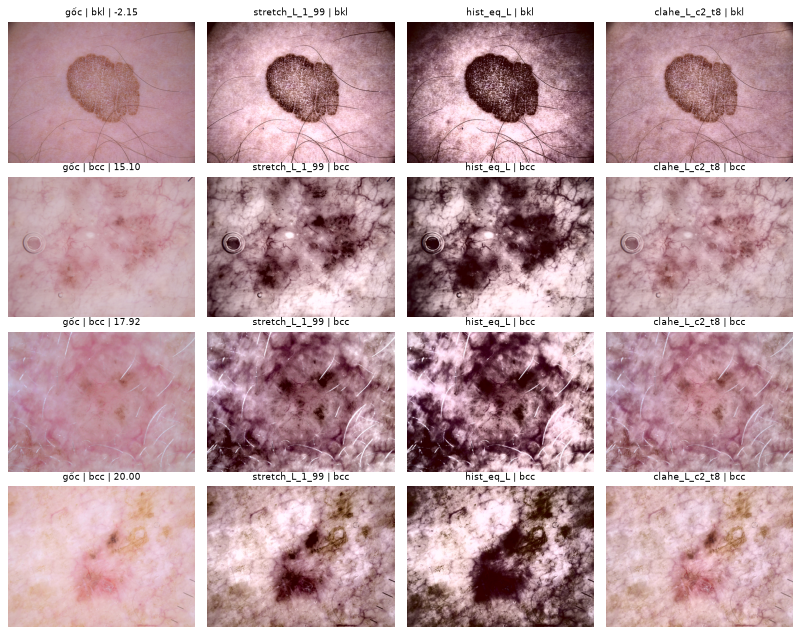

In [8]:
R.fig_before_after(D, KEY);

**Đo trên ảnh trước/sau (`train_fit`, không dùng CNN).** `contrast` là chênh da–tổn thương, `p5_p95` là khoảng phân vị 5–95 của mức xám, `dE76` là độ lệch màu so với ảnh gốc, `sigma_imm_224_ratio` là mức nhiễu sau xử lý so với ảnh gốc. `problem` là nhóm cờ, nhóm còn lại là đối chứng.

In [9]:
display(R.image_effect(KEY))

,group,method,n,contrast,p5_p95,dE76,sigma_imm_224_ratio
0,problem,none,275,16.542,39.0,0.000,1.000
1,problem,stretch_L_1_99,275,67.645,172.0,13.029,3.542
2,problem,hist_eq_L,275,100.378,225.0,23.569,5.508
4,problem,clahe_L_c2_t8,275,19.872,65.0,3.310,2.268
7,control,none,275,63.355,83.0,0.000,1.000
8,control,stretch_L_1_99,275,140.498,195.0,14.356,1.710
9,control,hist_eq_L,275,126.786,224.0,21.605,4.395
11,control,clahe_L_c2_t8,275,66.072,106.0,3.638,2.218


## 6. Chạy thực nghiệm

Mỗi cấu hình train lại 3 seed, so với baseline ghép cặp theo seed. **Quy tắc "khác biệt rõ" (2.5.0):** |Δ| > std giữa seed của baseline, CI95 bootstrap cụm lesion không chứa 0, và cả 3 seed cùng dấu.

In [10]:
# Train ở gốc repo bằng `scripts/run_problem_experiments.py all`; seed đã có metrics.json được đọc lại nên ô này chạy nhanh.
# Chỉ gọi đúng các cấu hình của vấn đề này để notebook tự kiểm chứng đủ dữ liệu.
runs = R.train(["baseline"] + R.PROBLEMS[KEY]["configs"])
display(runs.round(4))
RES = R.result_table(KEY)
display(R.result_view(RES))
BEST = R.pick_on_val(RES)
print("Cấu hình phân tích sâu, chọn theo val macro-F1 cao nhất:", BEST)

[03:12:36] [baseline seed 42] đã có metrics.json -> đọc lại


[03:12:36] [baseline seed 43] đã có metrics.json -> đọc lại


[03:12:36] [baseline seed 44] đã có metrics.json -> đọc lại


[03:12:36] [stretch_L_1_99 seed 42] đã có metrics.json -> đọc lại


[03:12:36] [stretch_L_1_99 seed 43] đã có metrics.json -> đọc lại


[03:12:36] [stretch_L_1_99 seed 44] đã có metrics.json -> đọc lại


... (5 outputs left out)

[03:12:36] [clahe_L_c2_t8 seed 44] đã có metrics.json -> đọc lại


,name,seed,best_epoch,val_macro_f1,test_macro_f1
0,baseline,42,11,0.7248,0.6784
1,baseline,43,17,0.7213,0.6935
2,baseline,44,15,0.7301,0.7103
3,stretch_L_1_99,42,15,0.6977,0.6002
4,stretch_L_1_99,43,5,0.6767,0.6120
5,stretch_L_1_99,44,17,0.7015,0.6341
6,hist_eq_L,42,18,0.6542,0.5760
7,hist_eq_L,43,12,0.6436,0.6079
8,hist_eq_L,44,12,0.6437,0.5665
9,clahe_L_c2_t8,42,13,0.7171,0.6713


,split,config,macro-F1,Δ macro-F1,CI95 Δ,dấu,kết luận,Δ bal. acc
0,val,baseline,0.7254 ± 0.0044,,,,,
1,val,stretch_L_1_99,0.6920 ± 0.0133,-0.0334,[-0.0669; +0.0014],0+/3-,không khác biệt rõ,-0.0403
2,val,hist_eq_L,0.6472 ± 0.0061,-0.0782,[-0.1251; -0.0388],0+/3-,tệ hơn rõ,-0.0821
3,val,clahe_L_c2_t8,0.7261 ± 0.0205,+0.0007,[-0.0255; +0.0256],1+/2-,không khác biệt rõ,+0.0025
4,test,baseline,0.6941 ± 0.0160,,,,,
5,test,stretch_L_1_99,0.6154 ± 0.0172,-0.0786,[-0.1149; -0.0442],0+/3-,tệ hơn rõ,-0.0764
6,test,hist_eq_L,0.5834 ± 0.0217,-0.1106,[-0.1508; -0.0698],0+/3-,tệ hơn rõ,-0.1031
7,test,clahe_L_c2_t8,0.6706 ± 0.0071,-0.0235,[-0.0524; +0.0088],0+/3-,không khác biệt rõ,-0.0209


Cấu hình phân tích sâu, chọn theo val macro-F1 cao nhất: clahe_L_c2_t8


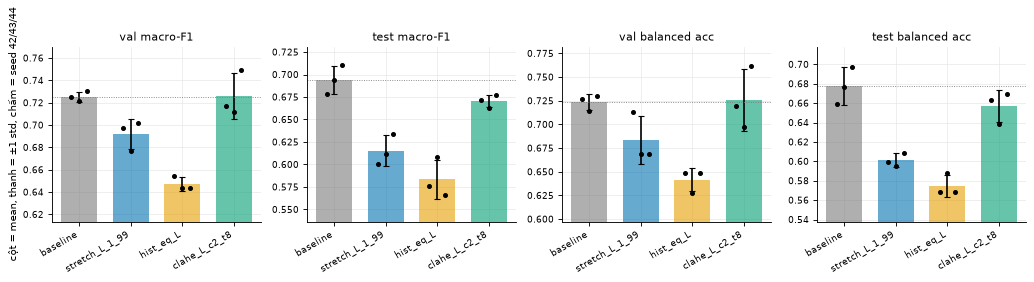

In [11]:
R.fig_results(KEY);

**F1 và recall từng lớp trên test** (trung bình 3 seed). Lớp `df`, `vasc` có ít ảnh nên dao động lớn.

In [12]:
display(R.per_class(KEY, 'test'))

F1                                          recall                                       
config baseline stretch_L_1_99 hist_eq_L clahe_L_c2_t8 baseline stretch_L_1_99 hist_eq_L clahe_L_c2_t8
lớp                                                                                                   
akiec     0.551          0.448     0.502         0.618    0.510          0.369     0.470         0.596
bcc       0.751          0.721     0.599         0.746    0.828          0.754     0.605         0.796
bkl       0.695          0.632     0.597         0.662    0.729          0.735     0.664         0.662
df        0.647          0.470     0.431         0.517    0.522          0.391     0.377         0.435
mel       0.546          0.452     0.490         0.564    0.518          0.435     0.544         0.605
nv        0.922          0.902     0.895         0.915    0.924          0.893     0.869         0.906
vasc      0.747          0.683     0.571         0.673    0.713          0.632     0.494         0.598

**Tác động riêng lên nhóm ảnh bị cờ.** DiD = Δ lỗi nhóm cờ − Δ lỗi phần còn lại. DiD âm nghĩa là phép xử lý giúp riêng nhóm cờ nhiều hơn phần còn lại.

In [13]:
display(R.target_group_effect(D, KEY).round(4))

,split,config,n nhóm cờ,lỗi baseline nhóm cờ,Δ lỗi nhóm cờ,Δ lỗi còn lại,DiD,CI thấp,CI cao
0,val,stretch_L_1_99,71,0.3099,-0.0516,0.0163,-0.0680,-0.1426,0.0149
1,val,hist_eq_L,71,0.3099,-0.0329,0.0498,-0.0827,-0.1817,0.0104
2,val,clahe_L_c2_t8,71,0.3099,-0.0657,0.0122,-0.0779,-0.1335,-0.0160
3,test,stretch_L_1_99,89,0.2509,0.0375,0.0409,-0.0035,-0.0650,0.0610
4,test,hist_eq_L,89,0.2509,0.0749,0.0580,0.0169,-0.0571,0.0949
5,test,clahe_L_c2_t8,89,0.2509,-0.0075,0.0124,-0.0198,-0.0799,0.0401


## 7. So sánh dự đoán trên mẫu 100 ảnh gặp vấn đề

**Cách lấy mẫu:** rút ngẫu nhiên 100 ảnh bị cờ ở val + test, seed 42, mỗi lesion một ảnh, không nhìn dự đoán. Dùng cả val vì ảnh bị cờ ở test có thể không đủ 100, và đây là thống kê ngoài mẫu huấn luyện.

**Trước** là dự đoán của baseline, **sau** là mô hình cùng seed huấn luyện trên ảnh đã xử lý. Ba dòng `baseline seed A→B` cho biết bao nhiêu ảnh đổi đúng/sai dù không xử lý gì, đó là mức cần vượt.

In [14]:
S = R.sample_100(D, KEY)
SD = R.sample_detail(S, KEY)
print(S.split_exp.value_counts().to_dict(), S.dx.value_counts().to_dict())
display(R.sample_summary(SD, KEY).round(4))

{'test': 60, 'val': 40} {'nv': 36, 'bkl': 24, 'bcc': 17, 'akiec': 14, 'mel': 5, 'df': 4}


,so sánh,đúng trước,đúng sau,sai→đúng,đúng→sai,ròng,McNemar p
0,stretch_L_1_99 | seed 42,69,73,14,10,4,0.5413
1,stretch_L_1_99 | seed 43,70,70,14,14,0,1.0000
2,stretch_L_1_99 | seed 44,77,70,10,17,-7,0.2478
3,stretch_L_1_99 | đa số 3 seed,73,74,11,10,1,1.0000
4,hist_eq_L | seed 42,69,71,15,13,2,0.8506
5,hist_eq_L | seed 43,70,73,15,12,3,0.7011
6,hist_eq_L | seed 44,77,66,6,17,-11,0.0347
7,hist_eq_L | đa số 3 seed,73,73,12,12,0,1.0000
8,clahe_L_c2_t8 | seed 42,69,72,14,11,3,0.6900
9,clahe_L_c2_t8 | seed 43,70,75,13,8,5,0.3833


**Xác suất của lớp đúng thay đổi thế nào.** Kiểm định dấu hạng Wilcoxon ghép theo ảnh, hiệu chỉnh Holm.

,config,Δ prob TB,Δ prob trung vị,số ảnh tăng,số ảnh giảm,Wilcoxon p,p Holm
0,stretch_L_1_99,-0.0199,-0.0069,43,57,0.2623,0.5247
1,hist_eq_L,-0.0411,-0.0184,37,63,0.0669,0.2006
2,clahe_L_c2_t8,0.0119,-0.0019,40,60,0.4311,0.5247


,n,đúng trước (đa số),đúng sau (đa số)
dx,,,
akiec,14,7,11
bcc,17,15,15
bkl,24,16,17
df,4,3,2
mel,5,0,0
nv,36,32,29


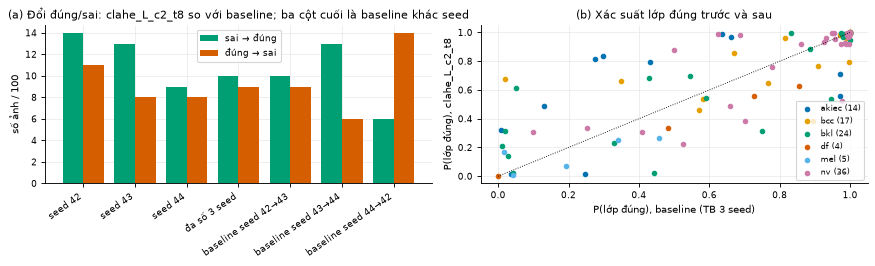

In [15]:
display(R.prob_change(SD, KEY).round(4))
display(R.sample_by_class(SD, BEST))
R.fig_sample(SD, KEY, BEST);

**Ảnh đổi đúng/sai theo đa số 3 seed** (cấu hình `BEST`, tối đa 4 ảnh mỗi chiều, lấy theo thứ tự `image_id`).

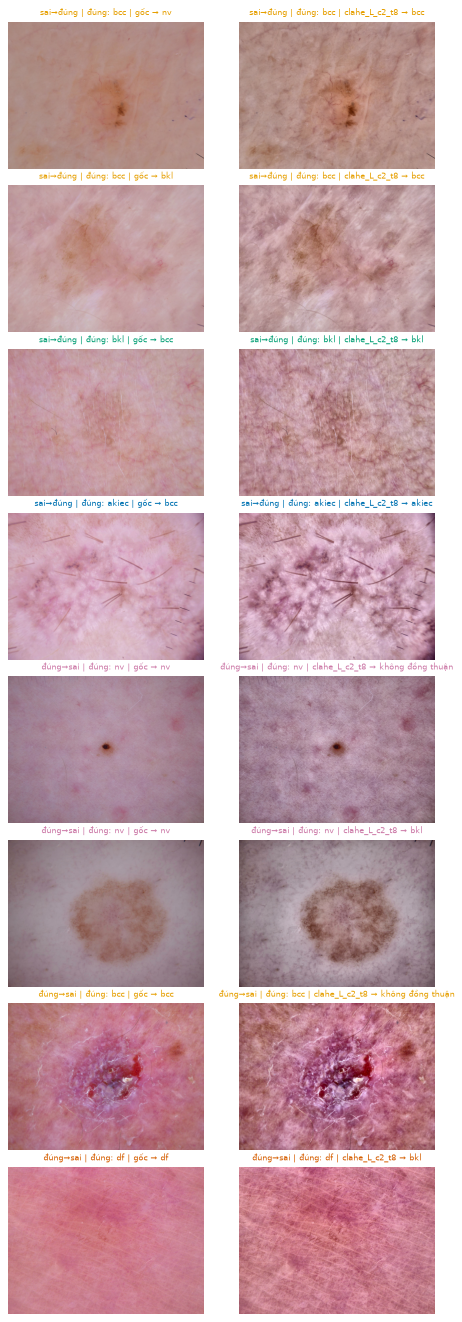

In [16]:
R.fig_sample_grid(SD, KEY, BEST);

## 8. Nhận xét

Mọi số liệu lấy từ lượt chạy thống nhất trên NVIDIA L40S (cùng baseline với toàn bộ báo cáo: val macro-F1 `0,7254 ± 0,0044`, test macro-F1 `0,6941 ± 0,0160`).

**1. Quan sát chính**
- **Mức độ vấn đề & giới hạn của bộ đo:** 435/10 015 ảnh (4,34%) có `contrast < 20` mức xám. Kiểm tra trực quan 24 ảnh ngẫu nhiên (`seed=42`, `lowcontrast_mask_audit.csv`) cho thấy mask Otsu thô bao **đúng** 8/24 ảnh, **một phần** 5/24 ảnh và **sai** 11/24 ảnh (thường bắt bóng tối ở rìa ảnh thay vì nốt nhỏ ở tâm).
- **Kết quả CNN (3 seed: 42, 43, 44):**
- `stretch_L_1_99`: val macro-F1 0,6920 (Δ -0,0334, CI95 [-0,0669; +0,0014], 0+/3- → *không khác biệt rõ*); test macro-F1 0,6154 (Δ -0,0786, CI95 [-0,1149; -0,0442], 0+/3- → **tệ hơn rõ**).
- `hist_eq_L`: val macro-F1 0,6472 (Δ -0,0782, CI95 [-0,1251; -0,0388], 0+/3- → *tệ hơn rõ*); test macro-F1 0,5834 (Δ -0,1106, CI95 [-0,1508; -0,0698], 0+/3- → **tệ hơn rõ**).
- `clahe_L_c2_t8`: val macro-F1 0,7261 (Δ +0,0007, CI95 [-0,0255; +0,0256], 1+/2- → *không khác biệt rõ*); test macro-F1 0,6706 (Δ -0,0235, CI95 [-0,0524; +0,0088], 0+/3- → **không khác biệt rõ**).

**2. Giải thích & Quyết định cho Pipeline (mục 2.6)**
- Giả thuyết **H-C được ủng hộ rõ:** hai phép biến đổi lược đồ toàn cục (`hist_eq_L`, `stretch_L_1_99`) đẩy chỉ số tương phản lên rất cao nhưng đồng thời khuếch đại nhiễu ở 224 gấp 3,5–5,5 lần và làm lệch khoảng cách màu $\Delta E_{76}$ (14–22 đơn vị, chủ yếu do dịch chuyển mạnh kênh độ sáng $|\Delta L^*|$ kèm lệch sắc độ nhẹ $\Delta ab pprox 1,4	ext{--}1,6$ khi cắt ngưỡng RGB) trên 95,7% ảnh bình thường, xóa nhòa ranh giới phân bố độ sáng tự nhiên giữa các lớp bệnh và dẫn tới sụt giảm nghiêm trọng macro-F1.
- `clahe_L_c2_t8` giới hạn hệ số khuếch đại cục bộ (`clip=2,0`, lưới $8\times 8$) nên tránh được tác hại của cân bằng toàn cục, song không vượt qua ngưỡng cải thiện rõ trên `val`.
- **Quyết định:** Loại bỏ `hist_eq_L` và `stretch_L_1_99`; không đưa tăng tương phản đại trà vào nhánh phân loại chính ở mục 2.6.